# 네팔 지진 피해 예측 — 실험 ③ Soft Voting 2~3개 모델 조합 (ExtraTrees · HGB · XGBoost · LightGBM)

실험 ③(변수 93개)과 같은 변수로 모델 4개를 각각 학습한 뒤, **예측 확률을 평균 내어(soft voting)** 등급을 고릅니다.

- 등급 불균형: 배수 없이 **class_weight**로만 다룹니다. 네 모델 모두 같은 가중치를 `sample_weight`로 넣습니다.
- 판정: 평균 확률이 가장 큰 등급을 그대로 고릅니다.
- 조합: 네 모델 중 2~3개를 골라 같은 비중으로 평균합니다 (10가지 조합 비교).
- 평가: Macro F1, Accuracy, Macro Precision, Macro Recall. 학습 70% / 검증 15% / 테스트 15%. 조합 선택은 검증으로만 하고, 테스트는 마지막에 한 번만 봅니다.

`nepal_building_damage.csv`를 이 노트북과 같은 폴더에 두고 위에서부터 차례로 실행하세요.
(처음 한 번만: `%pip install lightgbm xgboost scikit-learn pandas`)

## 1. 데이터 불러오기와 분할

In [ ]:
import numpy as np
import pandas as pd
import lightgbm as lgb

from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
from lightgbm import LGBMClassifier

SEED = 42
DATA_PATH = Path("./nepal_building_damage.csv")

# 데이터 불러오기
df = pd.read_csv(DATA_PATH)
print("원본 데이터 크기:", df.shape)

# 정답: 1, 2, 3등급 -> 0, 1, 2 (LightGBM은 0부터 시작하는 번호를 씀)
y = df["damage_grade"] - 1
X = df.drop(columns=["building_id", "damage_grade"])

# 학습 70% / 검증 15% / 테스트 15%
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp
)

# 행 번호를 0부터 다시 매기기 (뒤에서 행이 어긋나지 않게)
X_train = X_train.reset_index(drop=True)
X_val = X_val.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_val = y_val.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print("학습:", X_train.shape, "검증:", X_val.shape, "테스트:", X_test.shape)


원본 데이터 크기: (260601, 40)
학습: (182420, 38) 검증: (39090, 38) 테스트: (39091, 38)


## 2. 기존 9개 파생변수

In [11]:
geo_cols = ["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"]


def add_9_features(data):
    """한 건물(한 행) 안의 정보만 쓰는 변수 -> 누수 걱정 없음"""
    data = data.copy()

    # 1. 나이가 995(이상값)인지 표시
    data["is_995"] = (data["age"] == 995).astype(int)

    # 2. 면적 대비 높이
    data["height_area_ratio"] = data["height_percentage"] / data["area_percentage"].clip(lower=1)

    # 3. 구조재료 개수
    material_cols = [c for c in data.columns if c.startswith("has_superstructure_")]
    data["material_count"] = data[material_cols].sum(axis=1)

    # 4. 부가용도 개수
    use_cols = [c for c in data.columns if c.startswith("has_secondary_use_")]
    data["secondary_use_count"] = data[use_cols].sum(axis=1)

    # 5. 층당 높이
    data["height_per_floor"] = data["height_percentage"] / data["count_floors_pre_eq"].clip(lower=1)

    # 6. 철근콘크리트(RC) / 흙 재료 개수
    data["rc_count"] = (data["has_superstructure_rc_non_engineered"]
                        + data["has_superstructure_rc_engineered"])
    data["mud_count"] = (data["has_superstructure_adobe_mud"]
                         + data["has_superstructure_mud_mortar_stone"]
                         + data["has_superstructure_mud_mortar_brick"])

    # 7. 구조 조합 (글자 두 개를 붙여 새 범주 만들기)
    data["foundation_roof"] = data["foundation_type"] + "_" + data["roof_type"]
    data["ground_other_floor"] = data["ground_floor_type"] + "_" + data["other_floor_type"]
    data["foundation_ground"] = data["foundation_type"] + "_" + data["ground_floor_type"]
    data["surface_condition"] = data["land_surface_condition"] + "_" + data["ground_floor_type"]

    # 8. RC / 흙 사용 여부 (0 또는 1)
    data["has_mud"] = (data["mud_count"] > 0).astype(int)
    data["has_rc"] = (data["rc_count"] > 0).astype(int)

    return data


def add_region_age(train, other):
    """9. 지역별 평균 나이 - 반드시 학습 데이터에서만 계산"""
    train, other = train.copy(), other.copy()

    normal_age = train[train["age"] != 995]   # 995는 평균에서 제외
    overall_mean = normal_age["age"].mean()   # 처음 보는 지역에 쓸 값

    for geo in geo_cols:
        age_mean = normal_age.groupby(geo)["age"].mean()
        train[geo + "_age_mean"] = train[geo].map(age_mean).fillna(overall_mean)
        other[geo + "_age_mean"] = other[geo].map(age_mean).fillna(overall_mean)

    return train, other


## 3. 추가 파생변수

In [12]:
def add_more_features(data):
    data = data.copy()

    # 재료 종류별 개수
    data["cement_mortar_count"] = (data["has_superstructure_cement_mortar_stone"]
                                   + data["has_superstructure_cement_mortar_brick"])
    data["wood_bamboo_count"] = (data["has_superstructure_timber"]
                                 + data["has_superstructure_bamboo"])
    data["n_weak_material"] = (data["has_superstructure_adobe_mud"]
                               + data["has_superstructure_mud_mortar_stone"]
                               + data["has_superstructure_stone_flag"]
                               + data["has_superstructure_mud_mortar_brick"])

    # 대표 재료 그룹: 뒤에 쓴 줄이 우선 (RC > 시멘트 > 흙·돌 > 나무)
    data["material_group"] = "other"
    data.loc[data["wood_bamboo_count"] > 0, "material_group"] = "timber_bamboo"
    data.loc[data["n_weak_material"] > 0, "material_group"] = "mud_stone"
    data.loc[data["cement_mortar_count"] > 0, "material_group"] = "cement"
    data.loc[data["rc_count"] > 0, "material_group"] = "RC"

    # 기초 + 지붕 + 1층 바닥
    data["structure_type"] = (data["foundation_type"] + "_" + data["roof_type"]
                              + "_" + data["ground_floor_type"])

    # 층수 구간
    data["floor_band"] = "3F+"
    data.loc[data["count_floors_pre_eq"] == 1, "floor_band"] = "1F"
    data.loc[data["count_floors_pre_eq"] == 2, "floor_band"] = "2F"

    # 흙·돌 건물의 나이 (그 외 건물과 995는 0)
    is_weak = (data["material_group"] == "mud_stone") & (data["age"] != 995)
    data["weak_age"] = np.where(is_weak, data["age"], 0)

    return data


## 4. 튜터 아이디어: 지역 건물 특징과 피해 비율

지역 건물 특징은 정답을 쓰지 않습니다. 피해 비율은 정답을 쓰므로, 학습 데이터에서는 5-fold로 **자기 등급을 보지 않게** 계산합니다.

In [13]:
def add_region_profile(train, other):
    """지역별 건물 특징 - 정답(등급)은 쓰지 않고, 학습 데이터로만 계산"""
    train, other = train.copy(), other.copy()
    train["is_weak"] = (train["n_weak_material"] > 0).astype(int)

    for i, geo in enumerate(geo_cols, start=1):
        summary = train.groupby(geo).agg(
            building_count=("age", "size"),
            weak_ratio=("is_weak", "mean"),
            rc_ratio=("has_rc", "mean"),
        )
        for data in [train, other]:
            data[f"g{i}_building_count"] = data[geo].map(summary["building_count"]).fillna(0)
            data[f"g{i}_weak_ratio"] = data[geo].map(summary["weak_ratio"]).fillna(train["is_weak"].mean())
            data[f"g{i}_rc_ratio"] = data[geo].map(summary["rc_ratio"]).fillna(train["has_rc"].mean())
            # 지역 평균 나이와의 차이 (995는 0)
            data[f"g{i}_age_gap"] = np.where(data["age"] == 995, 0,
                                             data["age"] - data[f"{geo}_age_mean"])

    train = train.drop(columns=["is_weak"])
    return train, other


def make_rate_table(keys, y, smooth=20):
    """그룹별 1등급 비율(low_rate), 3등급 비율(high_rate)
    건물 수가 적은 그룹은 전체 평균 쪽으로 당겨서 계산(smooth)"""
    temp = pd.DataFrame({
        "key": keys.to_numpy(),
        "low": (y.to_numpy() == 0).astype(int),
        "high": (y.to_numpy() == 2).astype(int),
    })
    table = temp.groupby("key").agg(count=("low", "size"),
                                    low_sum=("low", "sum"),
                                    high_sum=("high", "sum"))
    table["low_rate"] = (table["low_sum"] + smooth * temp["low"].mean()) / (table["count"] + smooth)
    table["high_rate"] = (table["high_sum"] + smooth * temp["high"].mean()) / (table["count"] + smooth)
    return table


def add_damage_rates(train, other, y_train):
    """그룹별 피해 등급 비율 (정답을 쓰는 변수 -> 5-fold로 누수 방지)"""
    train, other = train.copy(), other.copy()
    y_train = y_train.reset_index(drop=True)

    # 지역 + 재료 그룹 이름표
    for data in [train, other]:
        for i, geo in enumerate(geo_cols, start=1):
            data[f"g{i}_material"] = data[geo].astype(str) + "_" + data["material_group"]

    keys = geo_cols + ["material_group", "structure_type",
                       "g1_material", "g2_material", "g3_material"]
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

    for key in keys:
        low_col, high_col = key + "_low_rate", key + "_high_rate"
        train[low_col] = np.nan
        train[high_col] = np.nan

        # 학습 데이터: 나머지 4조각으로 만든 표를 1조각에 붙임 (자기 정답은 안 봄)
        for fit_idx, oof_idx in folds.split(train, y_train):
            fit_y = y_train.iloc[fit_idx]
            table = make_rate_table(train[key].iloc[fit_idx], fit_y)
            part = train[key].iloc[oof_idx]
            train.loc[oof_idx, low_col] = part.map(table["low_rate"]).fillna((fit_y == 0).mean()).to_numpy()
            train.loc[oof_idx, high_col] = part.map(table["high_rate"]).fillna((fit_y == 2).mean()).to_numpy()

        # 검증/테스트: 학습 데이터 전체로 만든 표를 붙임
        table = make_rate_table(train[key], y_train)
        other[low_col] = other[key].map(table["low_rate"]).fillna((y_train == 0).mean())
        other[high_col] = other[key].map(table["high_rate"]).fillna((y_train == 2).mean())

    # 같은 재료 전체 대비, 이 지역의 피해율이 얼마나 높은지/낮은지
    for data in [train, other]:
        for i in [2, 3]:
            data[f"g{i}_material_high_gap"] = data[f"g{i}_material_high_rate"] - data["material_group_high_rate"]
            data[f"g{i}_material_low_gap"] = data[f"g{i}_material_low_rate"] - data["material_group_low_rate"]

    # 이름표 자체는 모델에 넣지 않음
    drop_cols = ["g1_material", "g2_material", "g3_material"]
    return train.drop(columns=drop_cols), other.drop(columns=drop_cols)


## 5. 범주형 변환과 변수 만들기

In [14]:
def to_category(train, other):
    """글자 변수와 지역 ID를 LightGBM 범주형으로 바꾸기
    (학습에 없던 값은 결측으로 처리)"""
    train, other = train.copy(), other.copy()
    cat_cols = train.select_dtypes(exclude=["number"]).columns.tolist()
    cat_cols = cat_cols + [c for c in geo_cols if c not in cat_cols]

    for col in cat_cols:
        train[col] = train[col].astype("category")
        known = train[col].cat.categories
        other[col] = pd.Categorical(other[col].where(other[col].isin(known)), categories=known)

    assert list(train.columns) == list(other.columns), "학습/검증 변수 구성이 다릅니다."
    return train, other


In [15]:
def make_features(train_raw, other_raw, y_train):
    train = add_9_features(train_raw)
    other = add_9_features(other_raw)
    train, other = add_region_age(train, other)

    train = add_more_features(train)
    other = add_more_features(other)

    train, other = add_region_profile(train, other)          # 실험 ③에서 추가
    train, other = add_damage_rates(train, other, y_train)   # 실험 ③에서 추가
    return to_category(train, other)


train_feat, val_feat = make_features(X_train, X_val, y_train)
print("학습:", train_feat.shape, "검증:", val_feat.shape)


학습: (182420, 93) 검증: (39090, 93)


## 6. 공통 설정

**class_weight**는 `exp3_classweight.ipynb` 7번에서 찾은 최적값으로 바꿔 넣으세요. 아래 값은 임시값입니다.

모델마다 범주형 변수를 받는 방식이 달라서 입력을 세 가지로 준비합니다.

| 모델 | 범주형 처리 |
|---|---|
| LightGBM, XGBoost | 범주형(category) 그대로 |
| HistGradientBoosting | 범주 255개 이하인 변수만 범주형, 나머지(geo_level_2/3_id 등)는 숫자 코드 |
| ExtraTrees | 범주형을 못 받아서 전부 숫자 코드 (처음 보는 값은 -1) |

In [16]:
import time
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import log_loss

# ▼ exp3_classweight.ipynb 7번 결과로 바꾸세요 (0=1등급, 1=2등급, 2=3등급)
CLASS_WEIGHT = {0: 1.9, 1: 1.0, 2: 1.3}


def make_sample_weight(y):
    """정답 등급마다 class_weight 값을 붙인 배열 (모든 모델에 공통으로 사용)"""
    return y.map(CLASS_WEIGHT).to_numpy()


def to_codes(data, missing_as_nan=False):
    """범주형 변수를 숫자 코드(0, 1, 2, ...)로 바꾸기. 처음 보는 값은 -1 또는 NaN"""
    data = data.copy()
    for col in data.select_dtypes(include="category").columns:
        codes = data[col].cat.codes.astype(float)
        if missing_as_nan:
            codes[codes < 0] = np.nan
        data[col] = codes
    return data


def hgb_categorical_mask(data):
    """HGB용: 범주 255개 이하인 범주형 변수만 True"""
    return [(str(data[c].dtype) == "category") and (data[c].cat.categories.size <= 255)
            for c in data.columns]


w_train = make_sample_weight(y_train)
w_val = make_sample_weight(y_val)
print("class_weight:", CLASS_WEIGHT)


class_weight: {0: 1.9, 1: 1.0, 2: 1.3}


## 7. 모델 4개 학습

모델마다 학습 함수를 만들어 둡니다. 8번 최종 재학습 때 같은 함수를 다시 씁니다.

- 검증 데이터를 주면 조기 종료로 트리 수를 정하고, `n_iter`를 주면 그 수만큼만 학습합니다.
- 조기 종료의 검증 logloss에도 같은 class_weight를 적용합니다.
- ExtraTrees는 조기 종료가 없어서 트리 수를 고정합니다.

⏱ 전체 5~15분 정도 걸립니다 (ExtraTrees가 메모리를 가장 많이 씁니다).

In [17]:
LGBM_PARAMS = {   # 이전 튜닝 시도 5의 설정
    "objective": "multiclass", "learning_rate": 0.03, "num_leaves": 127,
    "min_child_samples": 40, "subsample": 0.85, "subsample_freq": 1,
    "colsample_bytree": 0.7, "reg_lambda": 10, "cat_smooth": 60, "cat_l2": 30,
    "min_data_per_group": 200, "random_state": SEED, "n_jobs": -1, "verbosity": -1,
}


def train_lgbm(X, y, X_val=None, y_val=None, n_iter=3000):
    model = LGBMClassifier(**LGBM_PARAMS, n_estimators=n_iter)
    if X_val is None:
        model.fit(X, y, sample_weight=make_sample_weight(y))
    else:
        model.fit(X, y, sample_weight=make_sample_weight(y),
                  eval_set=[(X_val, y_val)], eval_sample_weight=[make_sample_weight(y_val)],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    return model


start = time.time()
lgbm_model = train_lgbm(train_feat, y_train, val_feat, y_val)
lgbm_iter = lgbm_model.best_iteration_
print(f"LightGBM 트리 수: {lgbm_iter} ({time.time() - start:.0f}초)")


c:\Users\wls03\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM 트리 수: 368 (14초)


In [18]:
XGB_PARAMS = {
    "objective": "multi:softprob", "learning_rate": 0.05, "max_depth": 8,
    "min_child_weight": 5, "subsample": 0.85, "colsample_bytree": 0.7,
    "reg_lambda": 5, "tree_method": "hist", "enable_categorical": True,
    "max_cat_to_onehot": 1, "eval_metric": "mlogloss",
    "random_state": SEED, "n_jobs": -1,
}


def train_xgb(X, y, X_val=None, y_val=None, n_iter=3000):
    if X_val is None:
        model = XGBClassifier(**XGB_PARAMS, n_estimators=n_iter)
        model.fit(X, y, sample_weight=make_sample_weight(y))
    else:
        model = XGBClassifier(**XGB_PARAMS, n_estimators=n_iter, early_stopping_rounds=100)
        model.fit(X, y, sample_weight=make_sample_weight(y),
                  eval_set=[(X_val, y_val)], sample_weight_eval_set=[make_sample_weight(y_val)],
                  verbose=False)
    return model


start = time.time()
xgb_model = train_xgb(train_feat, y_train, val_feat, y_val)
xgb_iter = xgb_model.best_iteration + 1
print(f"XGBoost 트리 수: {xgb_iter} ({time.time() - start:.0f}초)")


XGBoost 트리 수: 222 (28초)


In [19]:
# HGB 입력: 범주 많은 변수는 숫자 코드로
hgb_mask = hgb_categorical_mask(train_feat)
print("HGB 범주형으로 쓰는 변수 수:", sum(hgb_mask))

HGB_PARAMS = {
    "learning_rate": 0.05, "max_leaf_nodes": 63, "min_samples_leaf": 40,
    "l2_regularization": 5.0, "random_state": SEED,
}


def train_hgb(X, y, X_val=None, y_val=None, n_iter=3000):
    """HGB는 eval_set을 못 받아서, 검증 데이터가 있으면 직접 조기 종료 지점을 찾음"""
    X_codes = to_codes(X, missing_as_nan=True)
    if X_val is None:
        model = HistGradientBoostingClassifier(**HGB_PARAMS, max_iter=n_iter,
                                               categorical_features=hgb_mask, early_stopping=False)
        model.fit(X_codes, y, sample_weight=make_sample_weight(y))
        return model, n_iter

    # 트리를 하나씩 늘려 가며 검증 logloss 확인 (warm_start)
    model = HistGradientBoostingClassifier(**HGB_PARAMS, max_iter=0, warm_start=True,
                                           categorical_features=hgb_mask, early_stopping=False)
    X_val_codes = to_codes(X_val, missing_as_nan=True)
    w_v = make_sample_weight(y_val)
    best_loss, best_n, n = np.inf, 0, 0
    while n < n_iter:
        n += 50
        model.set_params(max_iter=n)
        model.fit(X_codes, y, sample_weight=make_sample_weight(y))
        loss = log_loss(y_val, model.predict_proba(X_val_codes), sample_weight=w_v)
        if loss < best_loss:
            best_loss, best_n = loss, n
        elif n - best_n >= 150:      # 150개 동안 나아지지 않으면 멈춤
            break
    # 가장 좋았던 트리 수로 다시 학습
    model = HistGradientBoostingClassifier(**HGB_PARAMS, max_iter=best_n,
                                           categorical_features=hgb_mask, early_stopping=False)
    model.fit(X_codes, y, sample_weight=make_sample_weight(y))
    return model, best_n


start = time.time()
hgb_model, hgb_iter = train_hgb(train_feat, y_train, val_feat, y_val)
print(f"HGB 트리 수: {hgb_iter} ({time.time() - start:.0f}초)")


HGB 범주형으로 쓰는 변수 수: 16
HGB 트리 수: 250 (130초)


In [20]:
ET_PARAMS = {
    "n_estimators": 200, "max_features": "sqrt", "min_samples_leaf": 5,   # 잎을 너무 잘게 나누면 메모리를 많이 씀
    "random_state": SEED, "n_jobs": -1,
}


def train_et(X, y):
    model = ExtraTreesClassifier(**ET_PARAMS)
    model.fit(to_codes(X), y, sample_weight=make_sample_weight(y))
    return model


start = time.time()
et_model = train_et(train_feat, y_train)
print(f"ExtraTrees 학습 완료 ({time.time() - start:.0f}초)")


ExtraTrees 학습 완료 (7초)


## 8. 모델별 단독 성능 (검증)

조합을 만들기 전에 네 모델 각각의 검증 성능을 봅니다. Precision과 Recall은 등급별 값을 단순 평균한 Macro 값입니다.

In [21]:
from sklearn.metrics import precision_score, recall_score

# 모델별 검증 예측 확률
val_proba = {
    "ExtraTrees": et_model.predict_proba(to_codes(val_feat)),
    "HGB":        hgb_model.predict_proba(to_codes(val_feat, missing_as_nan=True)),
    "XGBoost":    xgb_model.predict_proba(val_feat),
    "LightGBM":   lgbm_model.predict_proba(val_feat),
}
MODEL_NAMES = list(val_proba.keys())


def soft_vote(probas):
    """모델별 확률을 같은 비중으로 평균"""
    return sum(probas) / len(probas)


def scores(y_true, pred):
    """Macro F1, Accuracy, Macro Precision, Macro Recall"""
    return {
        "Macro F1":  f1_score(y_true, pred, average="macro"),
        "Accuracy":  accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, average="macro", zero_division=0),
        "Recall":    recall_score(y_true, pred, average="macro"),
    }


single_rows = [{"모델": name, **scores(y_val, p.argmax(axis=1))} for name, p in val_proba.items()]
single_df = pd.DataFrame(single_rows).sort_values("Macro F1", ascending=False)
display(single_df.round(4))


,모델,Macro F1,Accuracy,Precision,Recall
3,LightGBM,0.7187,0.7493,0.7119,0.7277
1,HGB,0.7168,0.7467,0.7073,0.7294
2,XGBoost,0.7123,0.7450,0.7078,0.7186
0,ExtraTrees,0.7123,0.7474,0.7103,0.7169


## 9. 2~3개 모델 조합 비교 (검증)

네 모델 중 **2개씩(6가지), 3개씩(4가지)** 골라 같은 비중으로 soft voting 하고, 네 가지 지표를 비교합니다. 확률만 다시 평균 내면 되므로 몇 초면 끝납니다.

검증 Macro F1이 가장 높은 조합을 10번 최종 테스트에 씁니다.

> 조합도 검증 데이터로 고르는 것이라 검증 점수는 조금 낙관적입니다. 상위 조합끼리 차이가 0.002 안이면 사실상 같다고 보세요.

In [22]:
from itertools import combinations

combo_rows = []
for k in [2, 3]:
    for combo in combinations(MODEL_NAMES, k):
        pred = soft_vote([val_proba[name] for name in combo]).argmax(axis=1)
        combo_rows.append({"조합": " + ".join(combo), "모델 수": k, **scores(y_val, pred)})

combo_df = pd.DataFrame(combo_rows).sort_values("Macro F1", ascending=False).reset_index(drop=True)
display(combo_df.round(4))

best_combo = combo_df.loc[0, "조합"]
SELECTED = best_combo.split(" + ")
best_single = single_df.iloc[0]

print("선택한 조합:", best_combo)
print("검증 Macro F1:", round(combo_df.loc[0, "Macro F1"], 4),
      f"/ 최고 단독 모델({best_single['모델']}) 대비:",
      f"{combo_df.loc[0, 'Macro F1'] - best_single['Macro F1']:+.4f}")

vote_val_pred = soft_vote([val_proba[name] for name in SELECTED]).argmax(axis=1)
print(classification_report(y_val + 1, vote_val_pred + 1, digits=4))


,조합,모델 수,Macro F1,Accuracy,Precision,Recall
0,HGB + LightGBM,2,0.7195,0.7495,0.7118,0.7296
1,ExtraTrees + HGB + LightGBM,3,0.7195,0.7506,0.7140,0.7272
2,ExtraTrees + HGB + XGBoost,3,0.7187,0.7501,0.7136,0.7260
3,HGB + XGBoost + LightGBM,3,0.7181,0.7488,0.7117,0.7266
4,ExtraTrees + HGB,2,0.7180,0.7494,0.7121,0.7265
5,ExtraTrees + LightGBM,2,0.7179,0.7501,0.7142,0.7237
6,HGB + XGBoost,2,0.7171,0.7477,0.7104,0.7261
7,XGBoost + LightGBM,2,0.7171,0.7482,0.7118,0.7242
8,ExtraTrees + XGBoost + LightGBM,3,0.7169,0.7489,0.7131,0.7227
9,ExtraTrees + XGBoost,2,0.7161,0.7490,0.7133,0.7211


선택한 조합: HGB + LightGBM
검증 Macro F1: 0.7195 / 최고 단독 모델(LightGBM) 대비: +0.0008
              precision    recall  f1-score   support

           1     0.6166    0.7046    0.6577      3768
           2     0.7819    0.7893    0.7856     22239
           3     0.7370    0.6949    0.7153     13083

    accuracy                         0.7495     39090
   macro avg     0.7118    0.7296    0.7195     39090
weighted avg     0.7509    0.7495    0.7497     39090



## 10. 최종 테스트

9번에서 고른 **조합과 각 모델의 트리 수를 고정**하고, 조합에 들어간 모델만 학습+검증(85%)으로 다시 학습한 뒤 soft voting으로 테스트를 한 번 평가합니다.

In [23]:
X_dev = pd.concat([X_train, X_val], ignore_index=True)
y_dev = pd.concat([y_train, y_val], ignore_index=True)
final_train, final_test = make_features(X_dev, X_test, y_dev)
hgb_mask = hgb_categorical_mask(final_train)   # 합친 데이터 기준으로 다시 계산

test_proba = {}
use = {name: (1 if name in SELECTED else 0) for name in MODEL_NAMES}

if use["ExtraTrees"] > 0:
    m = train_et(final_train, y_dev)
    test_proba["ExtraTrees"] = m.predict_proba(to_codes(final_test))
if use["HGB"] > 0:
    m, _ = train_hgb(final_train, y_dev, n_iter=hgb_iter)
    test_proba["HGB"] = m.predict_proba(to_codes(final_test, missing_as_nan=True))
if use["XGBoost"] > 0:
    m = train_xgb(final_train, y_dev, n_iter=xgb_iter)
    test_proba["XGBoost"] = m.predict_proba(final_test)
if use["LightGBM"] > 0:
    m = train_lgbm(final_train, y_dev, n_iter=lgbm_iter)
    test_proba["LightGBM"] = m.predict_proba(final_test)

test_pred = soft_vote(list(test_proba.values())).argmax(axis=1)

print("조합:", " + ".join(test_proba.keys()))
display(pd.DataFrame([scores(y_test, test_pred)], index=["테스트"]).round(4))
print(classification_report(y_test + 1, test_pred + 1, digits=4))
print("혼동행렬 (행: 실제, 열: 예측 / 1, 2, 3등급)")
print(confusion_matrix(y_test + 1, test_pred + 1))


조합: HGB + LightGBM


,Macro F1,Accuracy,Precision,Recall
테스트,0.7158,0.7473,0.708,0.7259


              precision    recall  f1-score   support

           1     0.6086    0.6949    0.6489      3769
           2     0.7814    0.7857    0.7836     22239
           3     0.7339    0.6970    0.7150     13083

    accuracy                         0.7473     39091
   macro avg     0.7080    0.7259    0.7158     39091
weighted avg     0.7488    0.7473    0.7476     39091

혼동행렬 (행: 실제, 열: 예측 / 1, 2, 3등급)
[[ 2619  1086    64]
 [ 1523 17474  3242]
 [  161  3803  9119]]


## 11. 혼동행렬 (테스트)

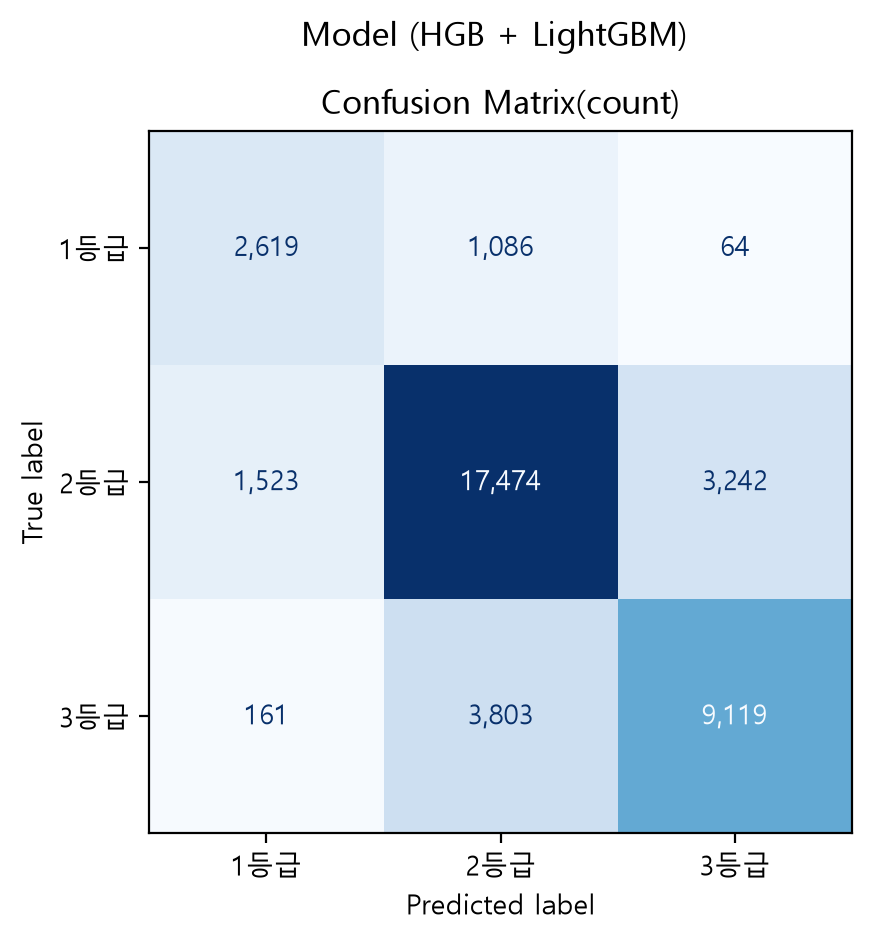

In [42]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
%config InlineBackend.figure_format = 'retina'

plt.rcParams["font.family"] = "Malgun Gothic"     # 한글 글꼴 (Mac은 "AppleGothic")
plt.rcParams["axes.unicode_minus"] = False

labels = ["1등급", "2등급", "3등급"]

# 왼쪽: 건수
ConfusionMatrixDisplay.from_predictions(
    y_test + 1, test_pred + 1, display_labels=labels,
    cmap="Blues", values_format=",d", colorbar=False)

plt.title(f"Model ({' + '.join(SELECTED)}) \n\nConfusion Matrix(count)")


plt.tight_layout()
plt.show()


## 12. 학습곡선 ① 트리 수에 따른 손실

7번에서 학습한 모델(학습 70%로 학습)의 트리 수에 따른 **학습 / 검증 logloss**입니다. 손실은 class_weight를 적용해 계산합니다 (조기 종료 기준과 같음).

- 검증 손실이 가장 낮은 지점(점선)이 조기 종료로 고른 트리 수입니다.
- 학습 손실은 계속 내려가는데 검증 손실이 다시 오르면 과적합이 시작된 것입니다.
- 빠르게 그리려고 학습 데이터는 30,000건만 뽑아서 계산합니다.
- ExtraTrees는 트리를 순서대로 쌓는 모델이 아니라서 제외합니다.

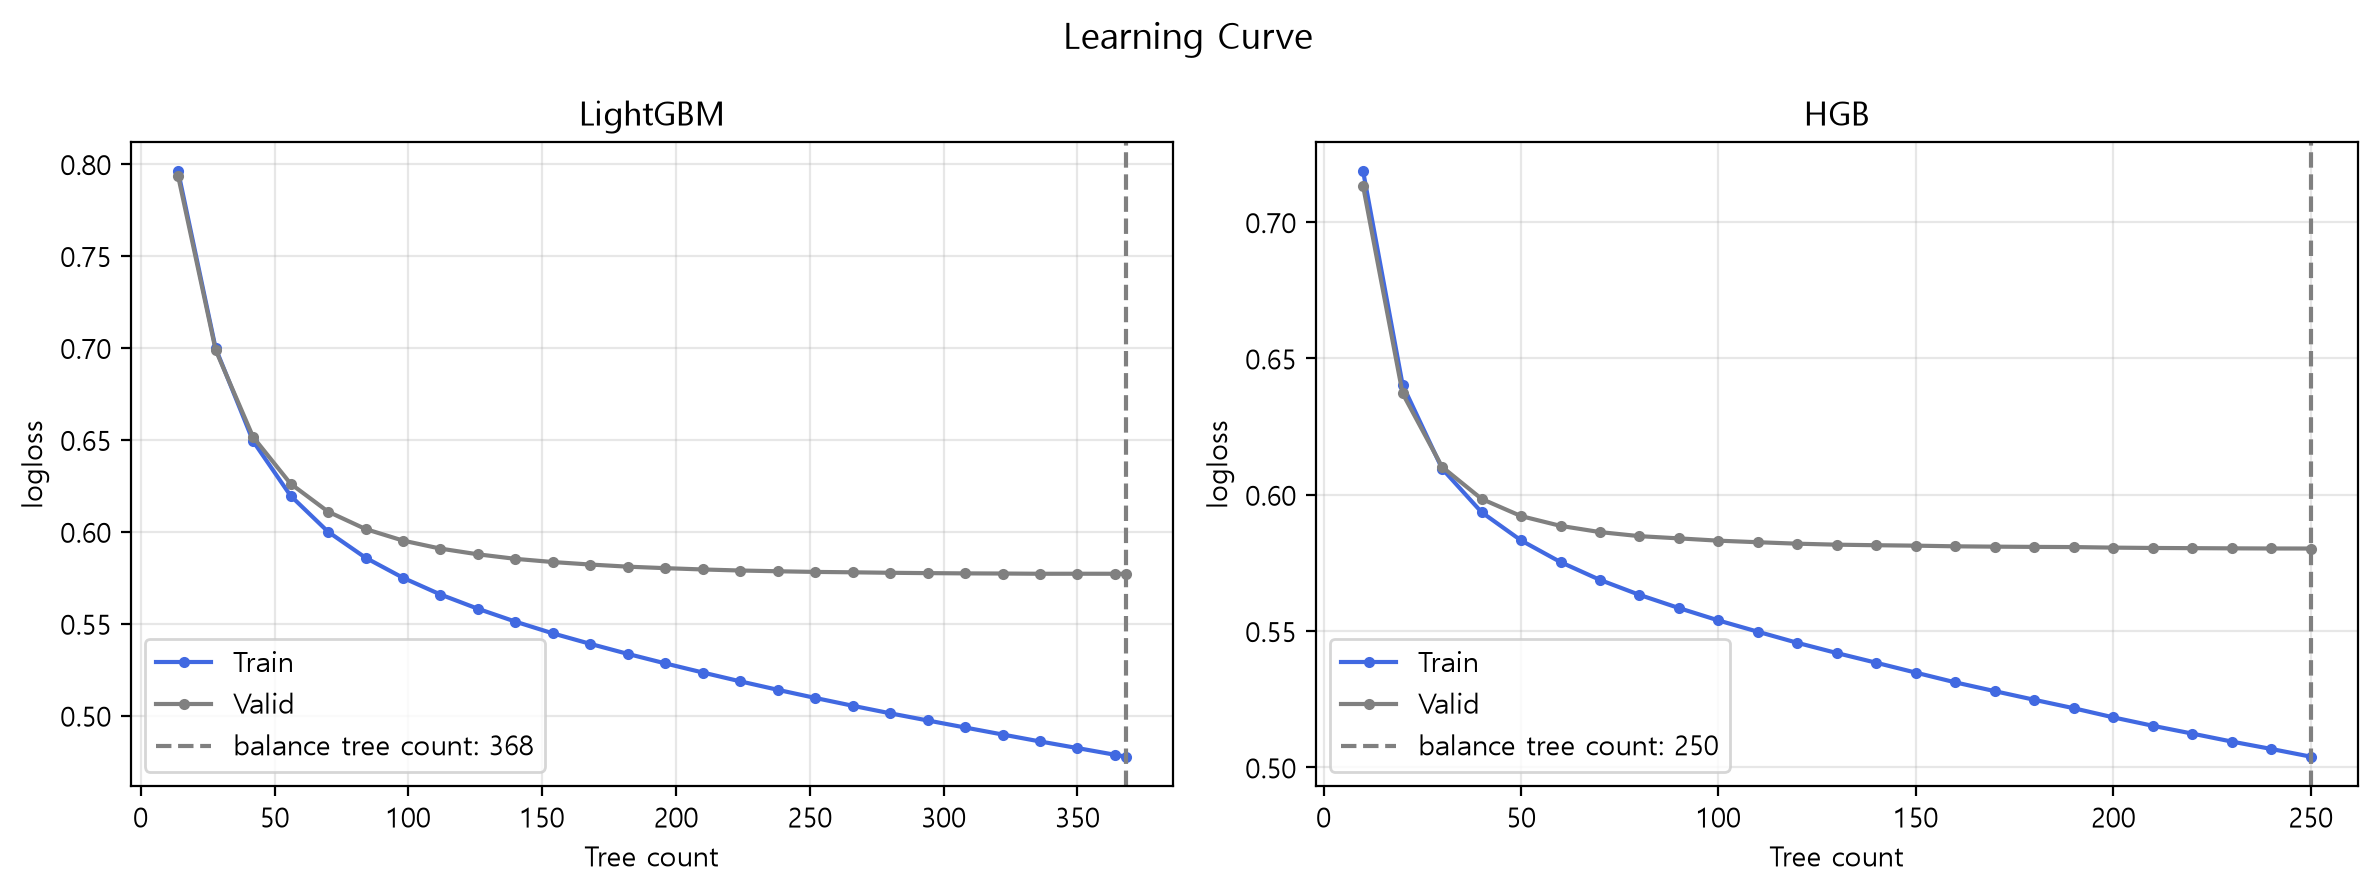

In [50]:
# 학습 데이터 일부만 사용 (속도)
curve_idx = np.random.RandomState(SEED).choice(len(train_feat), size=min(30000, len(train_feat)), replace=False)
tr_X, tr_y = train_feat.iloc[curve_idx], y_train.iloc[curve_idx]
w_tr, w_va = make_sample_weight(tr_y), make_sample_weight(y_val)


def loss_curve(predict_at, n_total, X_tr, X_va, step):
    """트리 수 n을 늘려 가며 학습/검증 logloss 계산"""
    ns, tr_loss, va_loss = [], [], []
    for n in list(range(step, n_total, step)) + [n_total]:
        ns.append(n)
        tr_loss.append(log_loss(tr_y, predict_at(X_tr, n), sample_weight=w_tr, labels=[0, 1, 2]))
        va_loss.append(log_loss(y_val, predict_at(X_va, n), sample_weight=w_va, labels=[0, 1, 2]))
    return ns, tr_loss, va_loss


curves = {}   # 모델 이름 -> (트리 수 목록, 학습 손실, 검증 손실, 고른 트리 수)

if "LightGBM" in SELECTED:
    n_total = lgbm_model.booster_.current_iteration()
    curves["LightGBM"] = (*loss_curve(lambda X, n: lgbm_model.predict_proba(X, num_iteration=n),
                                      n_total, tr_X, val_feat, step=max(10, n_total // 25)), lgbm_iter)

if "XGBoost" in SELECTED:
    n_total = xgb_model.get_booster().num_boosted_rounds()
    curves["XGBoost"] = (*loss_curve(lambda X, n: xgb_model.predict_proba(X, iteration_range=(0, n)),
                                     n_total, tr_X, val_feat, step=max(10, n_total // 25)), xgb_iter)

if "HGB" in SELECTED:
    # HGB는 트리를 하나씩 쌓은 결과를 차례로 돌려주는 staged_predict_proba 사용
    tr_codes = to_codes(tr_X, missing_as_nan=True)
    va_codes = to_codes(val_feat, missing_as_nan=True)
    ns, tr_loss, va_loss = [], [], []
    step = max(5, hgb_model.n_iter_ // 25)
    for n, (p_tr, p_va) in enumerate(zip(hgb_model.staged_predict_proba(tr_codes),
                                         hgb_model.staged_predict_proba(va_codes)), start=1):
        if n % step == 0 or n == hgb_model.n_iter_:
            ns.append(n)
            tr_loss.append(log_loss(tr_y, p_tr, sample_weight=w_tr, labels=[0, 1, 2]))
            va_loss.append(log_loss(y_val, p_va, sample_weight=w_va, labels=[0, 1, 2]))
    curves["HGB"] = (ns, tr_loss, va_loss, hgb_iter)

if not curves:
    print("선택한 조합에 트리를 순서대로 쌓는 모델이 없어 그릴 곡선이 없습니다.")
else:
    fig, axes = plt.subplots(1, len(curves), figsize=(6 * len(curves), 4.5), squeeze=False)
    for ax, (name, (ns, tr_loss, va_loss, best_n)) in zip(axes[0], curves.items()):
        ax.plot(ns, tr_loss, label="Train", marker="o", markersize=3, color='royalblue')
        ax.plot(ns, va_loss, label="Valid", marker="o", markersize=3, color = 'gray')
        ax.axvline(best_n, color="gray", linestyle="--", label=f"balance tree count: {best_n}")
        ax.set_title(f"{name}")
        ax.set_xlabel("Tree count")
        ax.set_ylabel("logloss")
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle("Learning Curve", fontsize=13)
    plt.tight_layout()
    plt.show()


## 13. 학습곡선 ② 학습 데이터 양에 따른 성능

학습 데이터를 10% → 100%로 늘려 가며 선택한 조합(soft voting)을 다시 학습하고, **학습 / 검증 Macro F1**을 비교합니다.

- 각 모델의 트리 수는 7번에서 정한 값으로 고정합니다.
- 검증 점수가 데이터를 늘릴수록 계속 오르면, 데이터가 더 있으면 더 좋아질 여지가 있다는 뜻입니다.
- 학습 점수와 검증 점수의 차이가 크면 과적합 정도가 크다는 뜻입니다.

⏱ 모델을 5번 다시 학습하므로 몇 분 걸립니다. 테스트 데이터는 쓰지 않습니다.

  10% (18,242건) | 학습 F1 0.9590 | 검증 F1 0.6949 | 12초
  25% (45,605건) | 학습 F1 0.8684 | 검증 F1 0.7051 | 16초
  50% (91,210건) | 학습 F1 0.8101 | 검증 F1 0.7130 | 22초
  75% (136,815건) | 학습 F1 0.7831 | 검증 F1 0.7174 | 31초
 100% (182,420건) | 학습 F1 0.7710 | 검증 F1 0.7195 | 38초


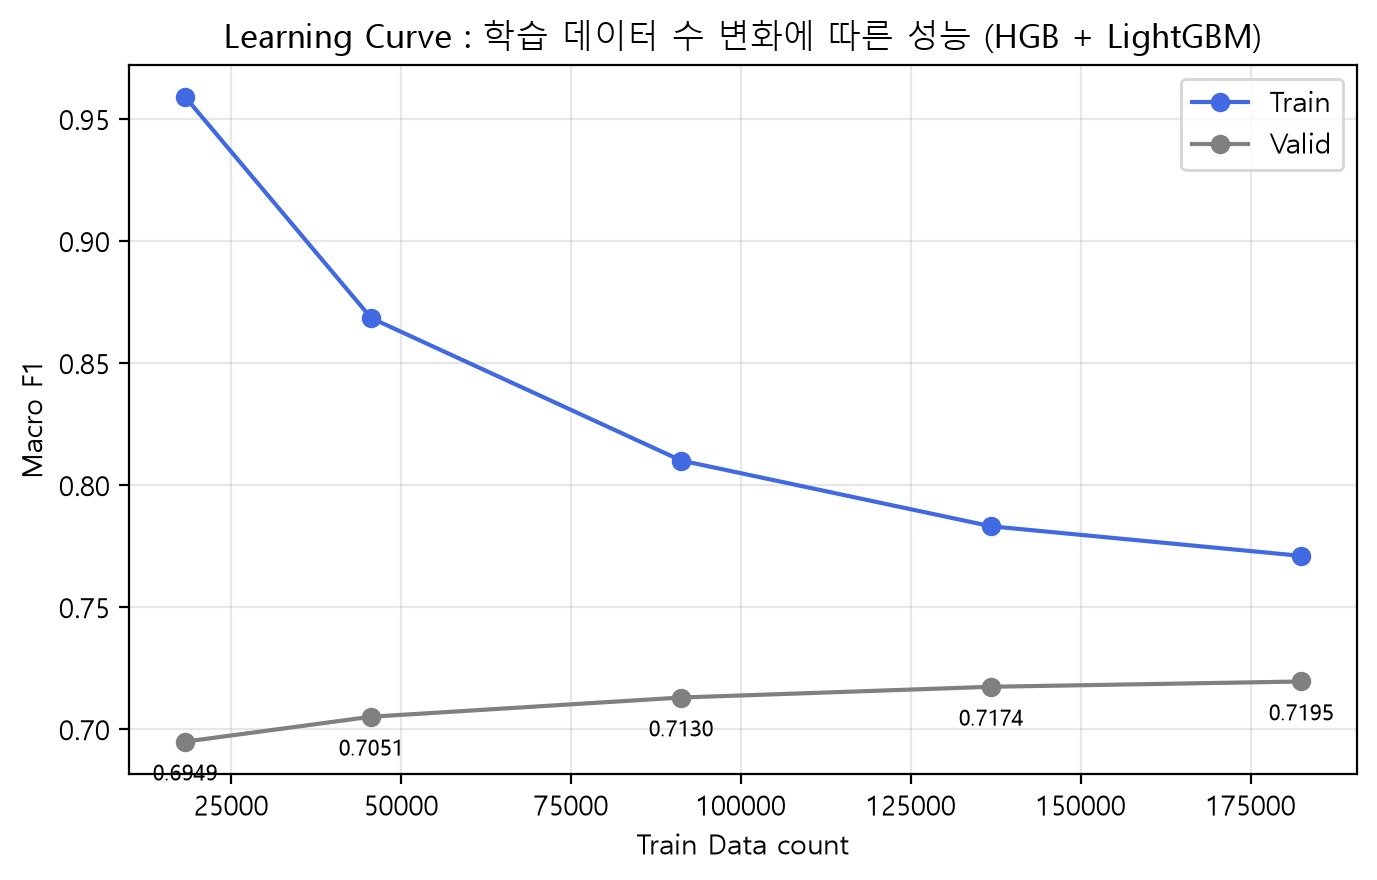

In [51]:
from sklearn.model_selection import train_test_split

hgb_mask = hgb_categorical_mask(train_feat)   # 10번에서 바뀐 값을 학습 데이터 기준으로 되돌림
FRACTIONS = [0.1, 0.25, 0.5, 0.75, 1.0]
size_rows = []

for frac in FRACTIONS:
    start = time.time()
    if frac < 1.0:
        sub_X, _, sub_y, _ = train_test_split(train_feat, y_train, train_size=frac,
                                              random_state=SEED, stratify=y_train)
    else:
        sub_X, sub_y = train_feat, y_train

    tr_probas, va_probas = [], []
    if "ExtraTrees" in SELECTED:
        m = train_et(sub_X, sub_y)
        tr_probas.append(m.predict_proba(to_codes(sub_X)))
        va_probas.append(m.predict_proba(to_codes(val_feat)))
    if "HGB" in SELECTED:
        m, _ = train_hgb(sub_X, sub_y, n_iter=hgb_iter)
        tr_probas.append(m.predict_proba(to_codes(sub_X, missing_as_nan=True)))
        va_probas.append(m.predict_proba(to_codes(val_feat, missing_as_nan=True)))
    if "XGBoost" in SELECTED:
        m = train_xgb(sub_X, sub_y, n_iter=xgb_iter)
        tr_probas.append(m.predict_proba(sub_X))
        va_probas.append(m.predict_proba(val_feat))
    if "LightGBM" in SELECTED:
        m = train_lgbm(sub_X, sub_y, n_iter=lgbm_iter)
        tr_probas.append(m.predict_proba(sub_X))
        va_probas.append(m.predict_proba(val_feat))

    tr_f1 = f1_score(sub_y, soft_vote(tr_probas).argmax(axis=1), average="macro")
    va_f1 = f1_score(y_val, soft_vote(va_probas).argmax(axis=1), average="macro")
    size_rows.append({"학습 비율": frac, "학습 건수": len(sub_y), "학습 F1": tr_f1, "검증 F1": va_f1})
    print(f"{frac:>5.0%} ({len(sub_y):,}건) | 학습 F1 {tr_f1:.4f} | 검증 F1 {va_f1:.4f} | {time.time() - start:.0f}초")

size_df = pd.DataFrame(size_rows)

plt.figure(figsize=(7, 4.5))
plt.plot(size_df["학습 건수"], size_df["학습 F1"], marker="o", label="Train", color='royalblue')
plt.plot(size_df["학습 건수"], size_df["검증 F1"], marker="o", label="Valid", color='gray')
for _, row in size_df.iterrows():
    plt.annotate(f"{row['검증 F1']:.4f}", (row["학습 건수"], row["검증 F1"]),
                 textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8)
plt.title(f"Learning Curve : 학습 데이터 수 변화에 따른 성능 ({' + '.join(SELECTED)})")
plt.xlabel("Train Data count")
plt.ylabel("Macro F1")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 14. Feature importance ① 모델별 내장 중요도

선택한 조합에 들어간 모델 각각의 중요도입니다. 7번에서 학습한 모델(학습 70%)을 사용합니다.

| 모델 | 중요도 기준 |
|---|---|
| LightGBM, XGBoost | gain: 그 변수로 나눴을 때 손실이 줄어든 양의 합 (분할 횟수보다 실제 기여에 가까움) |
| ExtraTrees | 불순도 감소량 합 |
| HGB | 내장 중요도가 없음 → 15번 permutation importance에서 확인 |

모델마다 단위가 달라서 **전체 합이 100%가 되도록 비율로** 바꿔 비교합니다.

HGB: 내장 중요도 없음 (15번 permutation importance 참고)


,LightGBM,평균
g3_material_low_rate,18.40,18.40
g3_material_high_rate,18.08,18.08
g2_material_low_rate,11.05,11.05
g2_material_high_rate,5.97,5.97
g3_material_high_gap,5.20,5.20
geo_level_2_id,5.10,5.10
geo_level_3_id_high_rate,4.61,4.61
geo_level_3_id_low_rate,2.52,2.52
g3_age_gap,1.96,1.96
geo_level_3_id,1.89,1.89


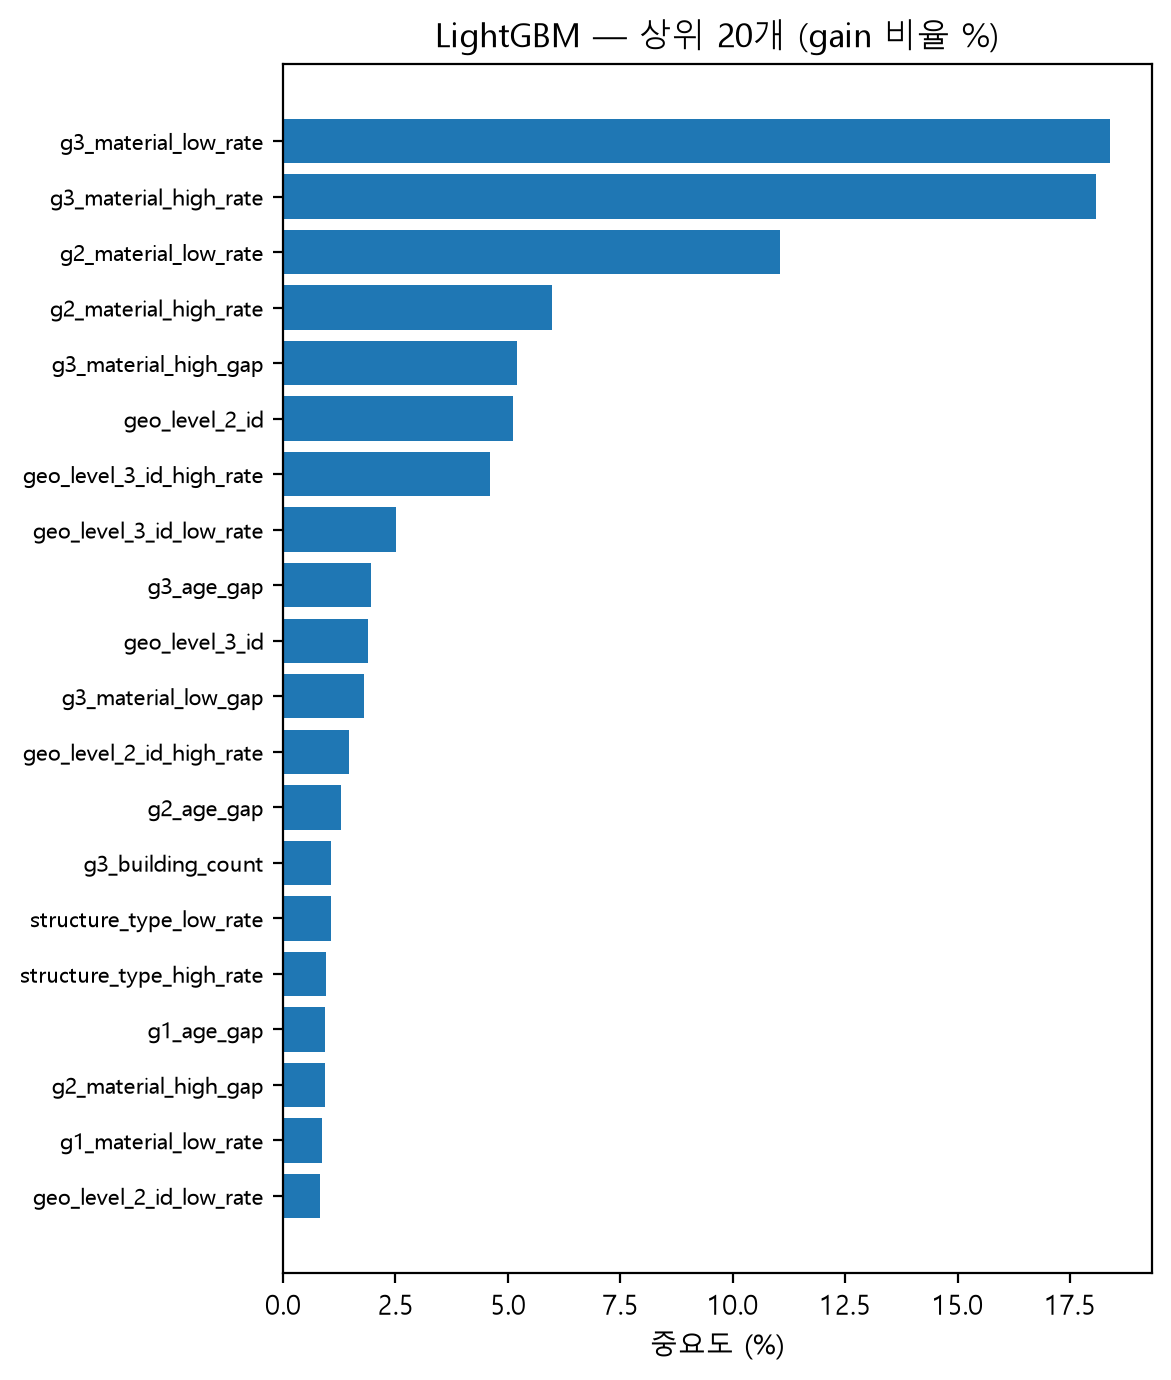

In [52]:
def builtin_importance(name):
    """모델별 내장 중요도를 비율(%)로 반환. 없으면 None"""
    cols = train_feat.columns
    if name == "LightGBM":
        values = pd.Series(lgbm_model.booster_.feature_importance(importance_type="gain"), index=cols)
    elif name == "XGBoost":
        score = xgb_model.get_booster().get_score(importance_type="gain")
        values = pd.Series(score).reindex(cols).fillna(0)
    elif name == "ExtraTrees":
        values = pd.Series(et_model.feature_importances_, index=cols)
    else:
        return None
    return values / values.sum() * 100


fi_table = {}
for name in SELECTED:
    imp = builtin_importance(name)
    if imp is None:
        print(f"{name}: 내장 중요도 없음 (15번 permutation importance 참고)")
    else:
        fi_table[name] = imp

if fi_table:
    fi_df = pd.DataFrame(fi_table)
    fi_df["평균"] = fi_df.mean(axis=1)
    fi_df = fi_df.sort_values("평균", ascending=False)
    display(fi_df.head(20).round(2))

    TOP = 20
    fig, axes = plt.subplots(1, len(fi_table), figsize=(6 * len(fi_table), 7), squeeze=False)
    for ax, name in zip(axes[0], fi_table):
        top = fi_table[name].sort_values(ascending=True).tail(TOP)
        ax.barh(top.index, top.values)
        ax.set_title(f"{name} — 상위 {TOP}개 (gain 비율 %)" if name != "ExtraTrees"
                     else f"{name} — 상위 {TOP}개 (불순도 감소 비율 %)")
        ax.set_xlabel("중요도 (%)")
        ax.tick_params(axis="y", labelsize=8)
    plt.tight_layout()
    plt.show()


## 15. Feature importance ② Soft voting 전체의 permutation importance

모델 종류와 상관없이 **조합 전체(soft voting)** 기준으로 변수의 중요도를 봅니다.

- 검증 데이터에서 변수 하나의 값만 무작위로 섞은 뒤, Macro F1이 얼마나 떨어지는지 잽니다.
- 많이 떨어질수록 조합이 그 변수에 크게 의존한다는 뜻입니다. 0 근처나 음수면 없어도 거의 상관없는 변수입니다.
- 빠르게 하려고 검증 데이터 10,000건, 변수마다 3번 반복합니다. ⏱ 3~5분 정도 걸립니다.
- 비슷한 정보를 가진 변수가 여럿이면(예: geo_level_3_id와 geo_level_3_id_low_rate) 하나를 섞어도 다른 변수가 대신해서 중요도가 낮게 나올 수 있습니다.

섞기 전 Macro F1: 0.7186
계산 시간: 58초


,변수,F1 감소 (평균),F1 감소 (표준편차)
0,g3_material_low_rate,0.0477,0.0021
1,g3_material_high_rate,0.0283,0.0030
2,geo_level_3_id_low_rate,0.0267,0.0009
3,g2_material_low_rate,0.0250,0.0040
4,g3_age_gap,0.0064,0.0006
5,geo_level_1_id,0.0054,0.0008
6,g2_material_high_rate,0.0054,0.0002
7,count_families,0.0052,0.0007
8,g3_building_count,0.0041,0.0011
9,structure_type,0.0040,0.0004


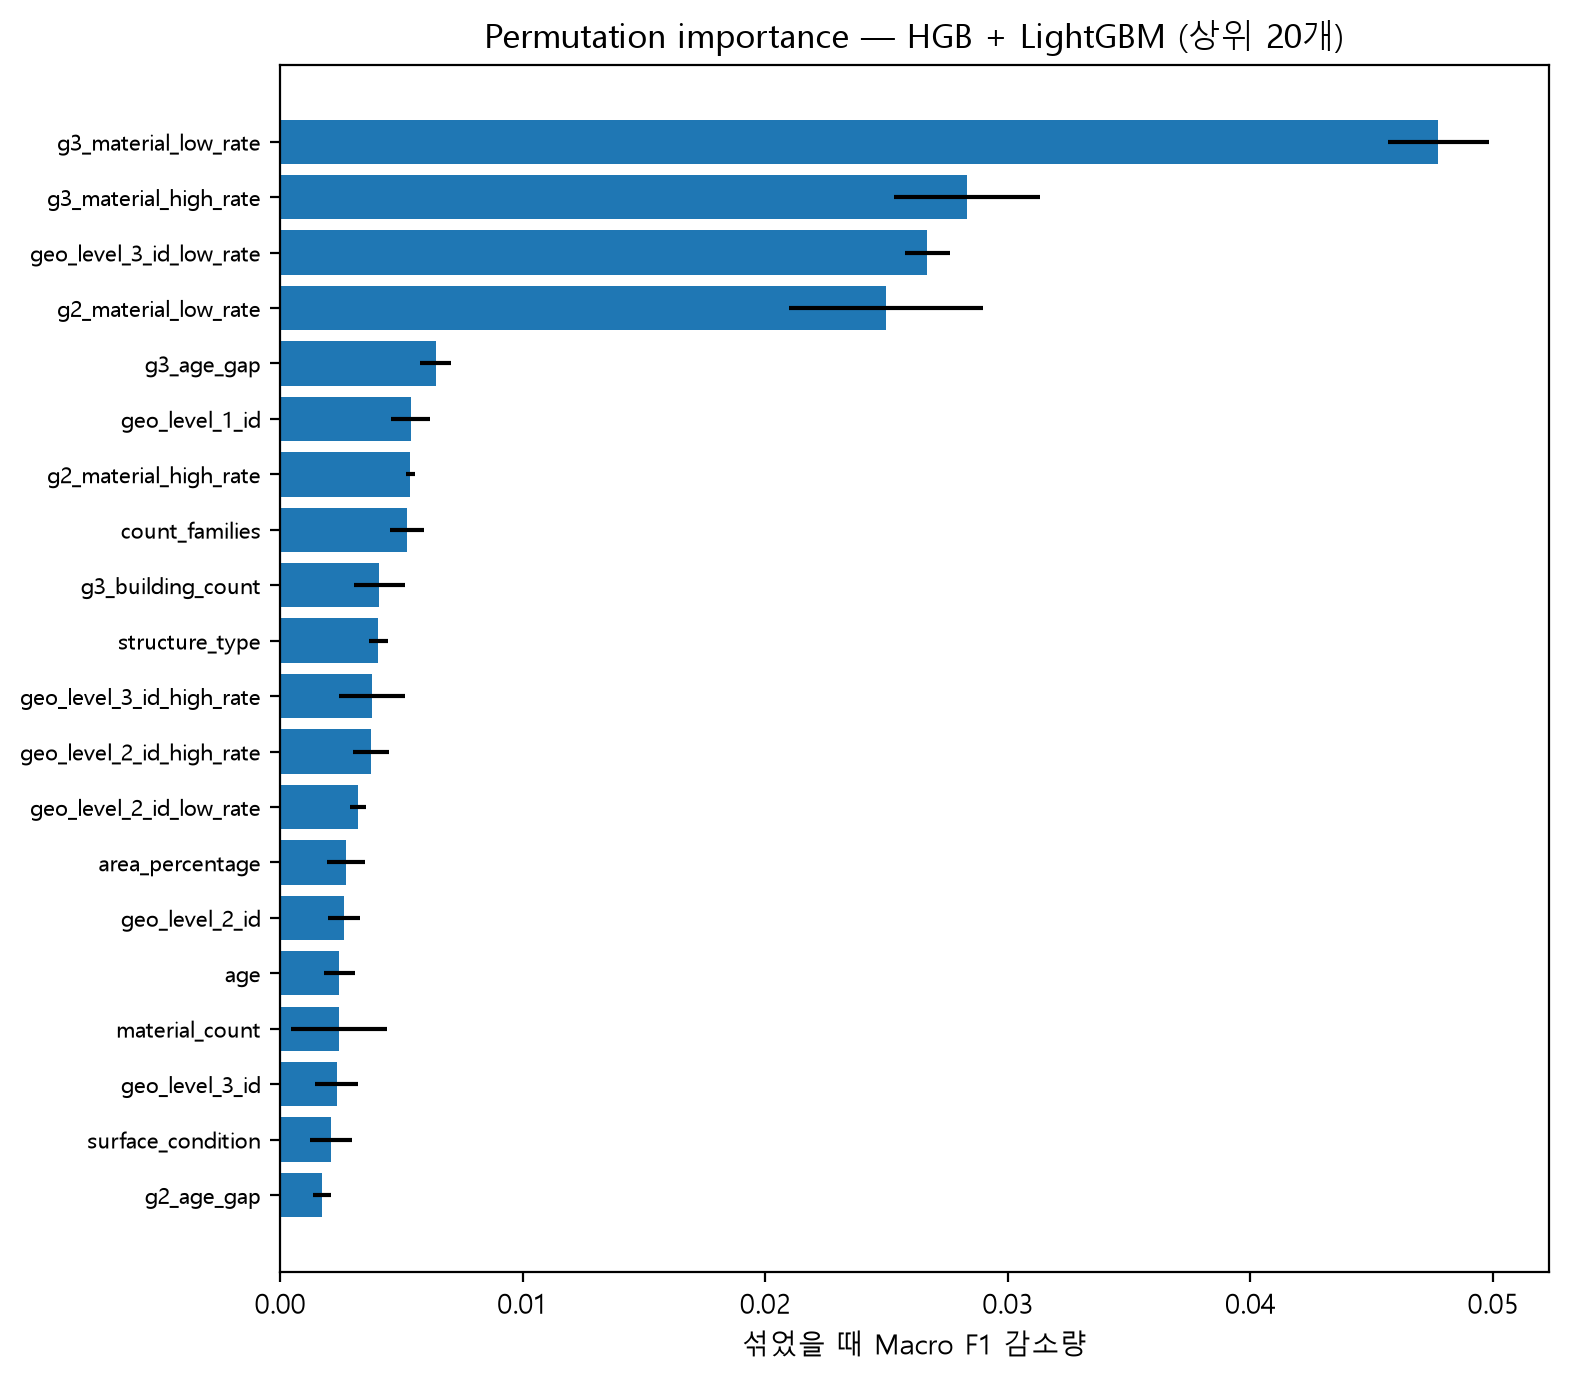

중요도 0 이하인 변수 수: 31 / 93


In [53]:
def vote_proba(X):
    """선택한 조합의 soft voting 확률 (7번 모델 사용)"""
    probas = []
    for name in SELECTED:
        if name == "ExtraTrees":
            probas.append(et_model.predict_proba(to_codes(X)))
        elif name == "HGB":
            probas.append(hgb_model.predict_proba(to_codes(X, missing_as_nan=True)))
        elif name == "XGBoost":
            probas.append(xgb_model.predict_proba(X))
        elif name == "LightGBM":
            probas.append(lgbm_model.predict_proba(X))
    return soft_vote(probas)


N_ROWS, N_REPEATS = 10000, 3
rng = np.random.RandomState(SEED)
pi_idx = rng.choice(len(val_feat), size=min(N_ROWS, len(val_feat)), replace=False)
pi_X = val_feat.iloc[pi_idx].reset_index(drop=True)
pi_y = y_val.iloc[pi_idx].reset_index(drop=True)

base_f1 = f1_score(pi_y, vote_proba(pi_X).argmax(axis=1), average="macro")
print("섞기 전 Macro F1:", round(base_f1, 4))

start = time.time()
pi_rows = []
for col in pi_X.columns:
    drops = []
    for r in range(N_REPEATS):
        shuffled = pi_X.copy()
        perm = rng.permutation(len(shuffled))
        shuffled[col] = shuffled[col].iloc[perm].values   # 범주형도 형식 유지
        f1 = f1_score(pi_y, vote_proba(shuffled).argmax(axis=1), average="macro")
        drops.append(base_f1 - f1)
    pi_rows.append({"변수": col, "F1 감소 (평균)": np.mean(drops), "F1 감소 (표준편차)": np.std(drops)})
print(f"계산 시간: {time.time() - start:.0f}초")

pi_df = pd.DataFrame(pi_rows).sort_values("F1 감소 (평균)", ascending=False).reset_index(drop=True)
display(pi_df.head(20).round(4))

top = pi_df.head(20).iloc[::-1]
plt.figure(figsize=(8, 7))
plt.barh(top["변수"], top["F1 감소 (평균)"], xerr=top["F1 감소 (표준편차)"])
plt.title(f"Permutation importance — {' + '.join(SELECTED)} (상위 20개)")
plt.xlabel("섞었을 때 Macro F1 감소량")
plt.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

print("중요도 0 이하인 변수 수:", (pi_df["F1 감소 (평균)"] <= 0).sum(), "/", len(pi_df))


## 16. SHAP (LightGBM)

SHAP은 **각 건물의 예측에 변수 하나하나가 얼마나, 어느 방향으로** 기여했는지 보여 줍니다. 조합 중 가장 성능이 좋은 LightGBM(7번 모델)으로 계산합니다.

- soft voting은 여러 모델의 확률을 평균한 것이라 SHAP 값을 그대로 합칠 수 없어서, 대표 모델 하나로 해석합니다.
- LightGBM 내장 기능(`pred_contrib=True`)으로 SHAP 값을 계산하고, 그림만 `shap` 라이브러리로 그립니다. 범주형 변수도 문제없이 계산됩니다.
- 검증 데이터 5,000건으로 계산합니다.
- 값의 단위는 확률이 아니라 **log-odds(로그 오즈)** 입니다. 양수면 그 등급일 가능성을 높이는 방향입니다.

(처음 한 번만: `%pip install shap`)

c:\Users\wls03\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,1등급,2등급,3등급,합계
g2_material_low_rate,0.5198,0.0149,0.1239,0.6586
g3_material_high_rate,0.0877,0.1827,0.3822,0.6526
geo_level_2_id,0.3985,0.0970,0.1264,0.6220
g3_material_low_rate,0.4201,0.0670,0.1159,0.6030
g2_material_high_rate,0.0845,0.0654,0.1526,0.3026
geo_level_3_id,0.2343,0.0271,0.0326,0.2940
geo_level_3_id_high_rate,0.0226,0.0683,0.1514,0.2424
geo_level_3_id_low_rate,0.1843,0.0421,0.0145,0.2410
g3_age_gap,0.1313,0.0192,0.0820,0.2326
ground_other_floor,0.0960,0.0450,0.0528,0.1938


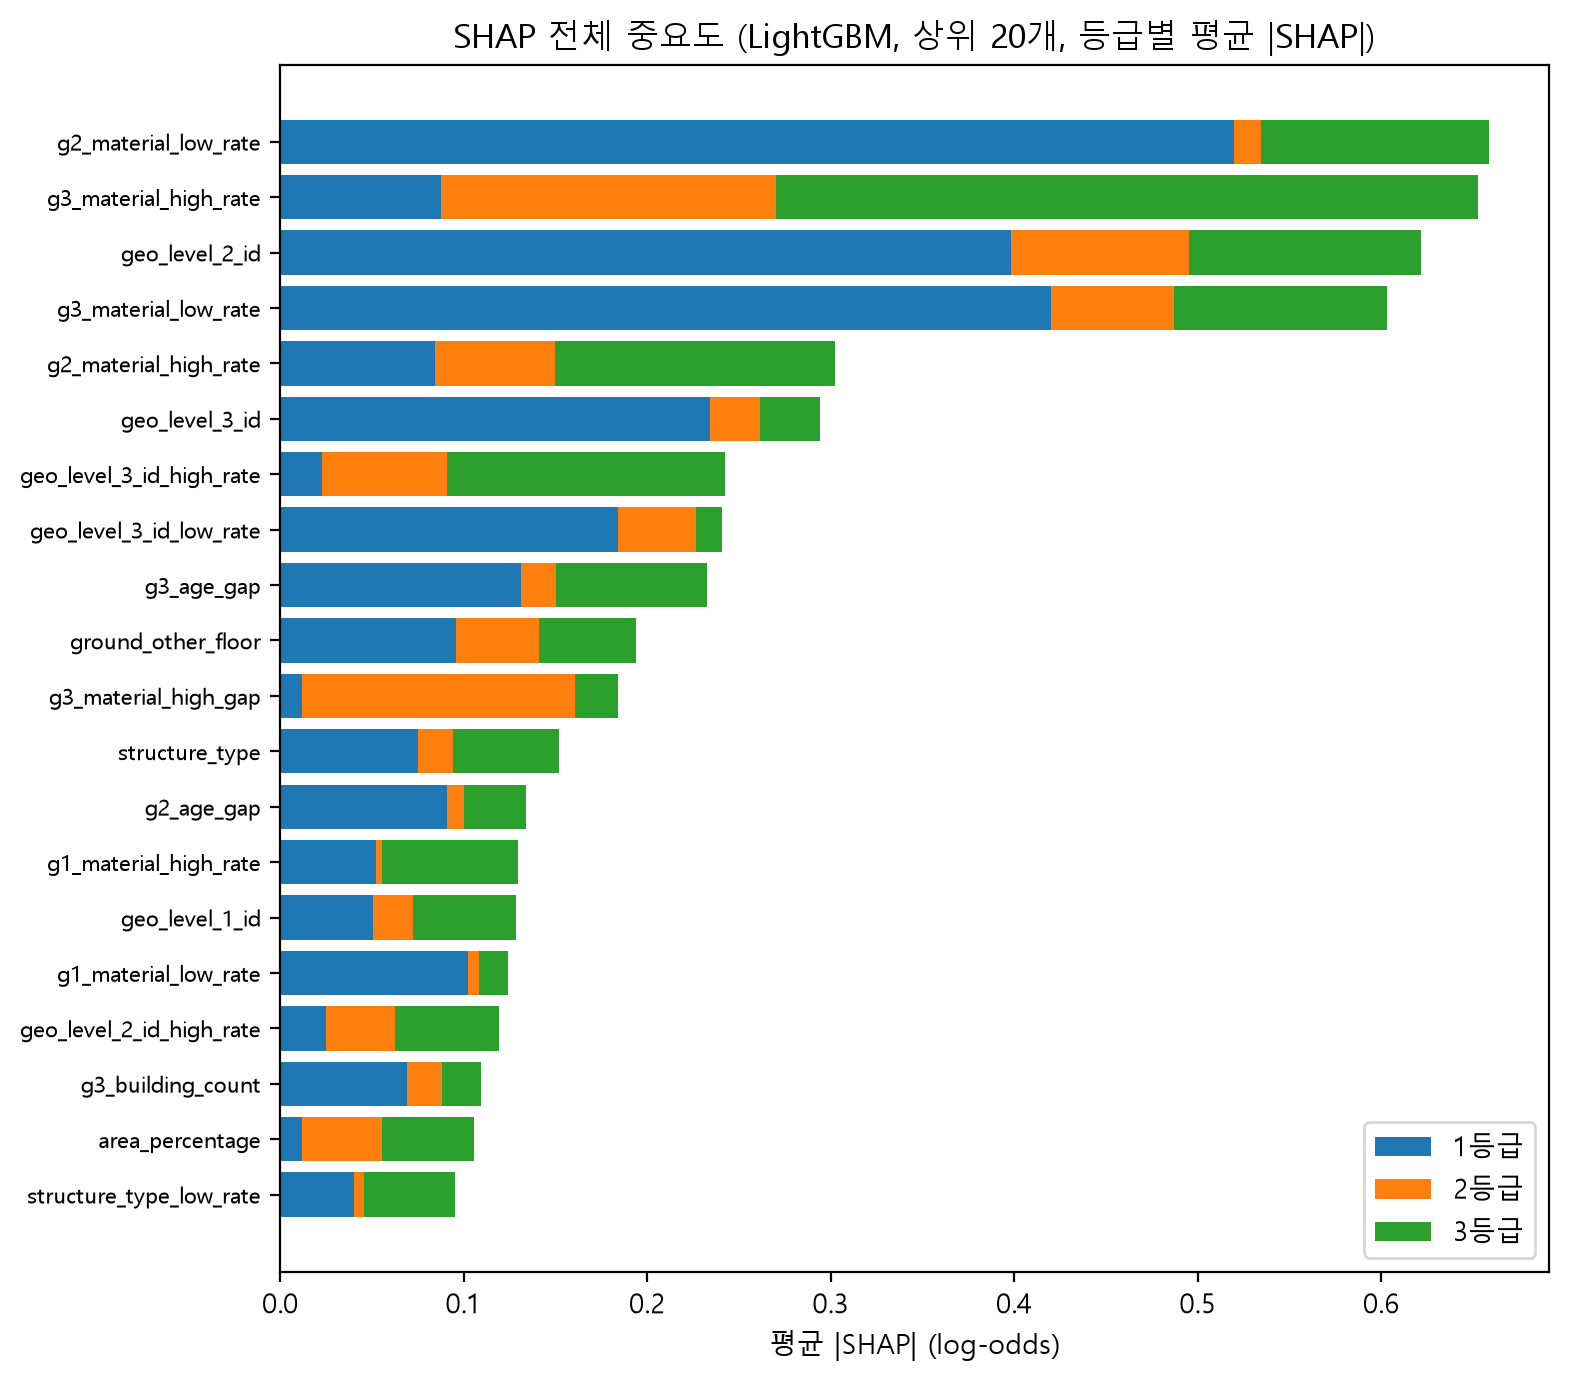

In [56]:
import shap

N_SHAP = 5000
shap_idx = np.random.RandomState(SEED).choice(len(val_feat), size=min(N_SHAP, len(val_feat)), replace=False)
shap_X = val_feat.iloc[shap_idx]

# LightGBM 내장 SHAP: (건수, (변수 수 + 1) × 3) 모양 -> 등급별로 나누기 (마지막 칸은 기준값)
contrib = lgbm_model.predict(shap_X, pred_contrib=True)
n_feat = shap_X.shape[1]
contrib = np.asarray(contrib).reshape(len(shap_X), 3, n_feat + 1)
shap_values = [contrib[:, k, :n_feat] for k in range(3)]   # 등급별 SHAP 값
base_values = [contrib[0, k, n_feat] for k in range(3)]

# 그림의 색(변수 값의 크고 작음)을 위해 범주형은 숫자 코드로
shap_X_codes = to_codes(shap_X)
labels = ["1등급", "2등급", "3등급"]

# 전체 중요도: 세 등급의 |SHAP| 평균을 합침
mean_abs = pd.DataFrame({labels[k]: np.abs(shap_values[k]).mean(axis=0) for k in range(3)},
                        index=shap_X.columns)
mean_abs["합계"] = mean_abs.sum(axis=1)
mean_abs = mean_abs.sort_values("합계", ascending=False)
display(mean_abs.head(20).round(4))

top = mean_abs.head(20).iloc[::-1]
plt.figure(figsize=(8, 7))
left = np.zeros(len(top))
for label in labels:
    plt.barh(top.index, top[label], left=left, label=label)
    left += top[label].to_numpy()
plt.title("SHAP 전체 중요도 (LightGBM, 상위 20개, 등급별 평균 |SHAP|)")
plt.xlabel("평균 |SHAP| (log-odds)")
plt.tick_params(axis="y", labelsize=8)
plt.legend()
plt.tight_layout()
plt.show()


### 등급별 SHAP summary plot

점 하나가 건물 하나입니다. 가로 위치는 그 등급 예측에 대한 기여(오른쪽일수록 그 등급일 가능성↑), 색은 변수 값(빨강=큼, 파랑=작음)입니다. 범주형 변수는 숫자 코드라 색의 크고 작음에 의미가 없습니다.

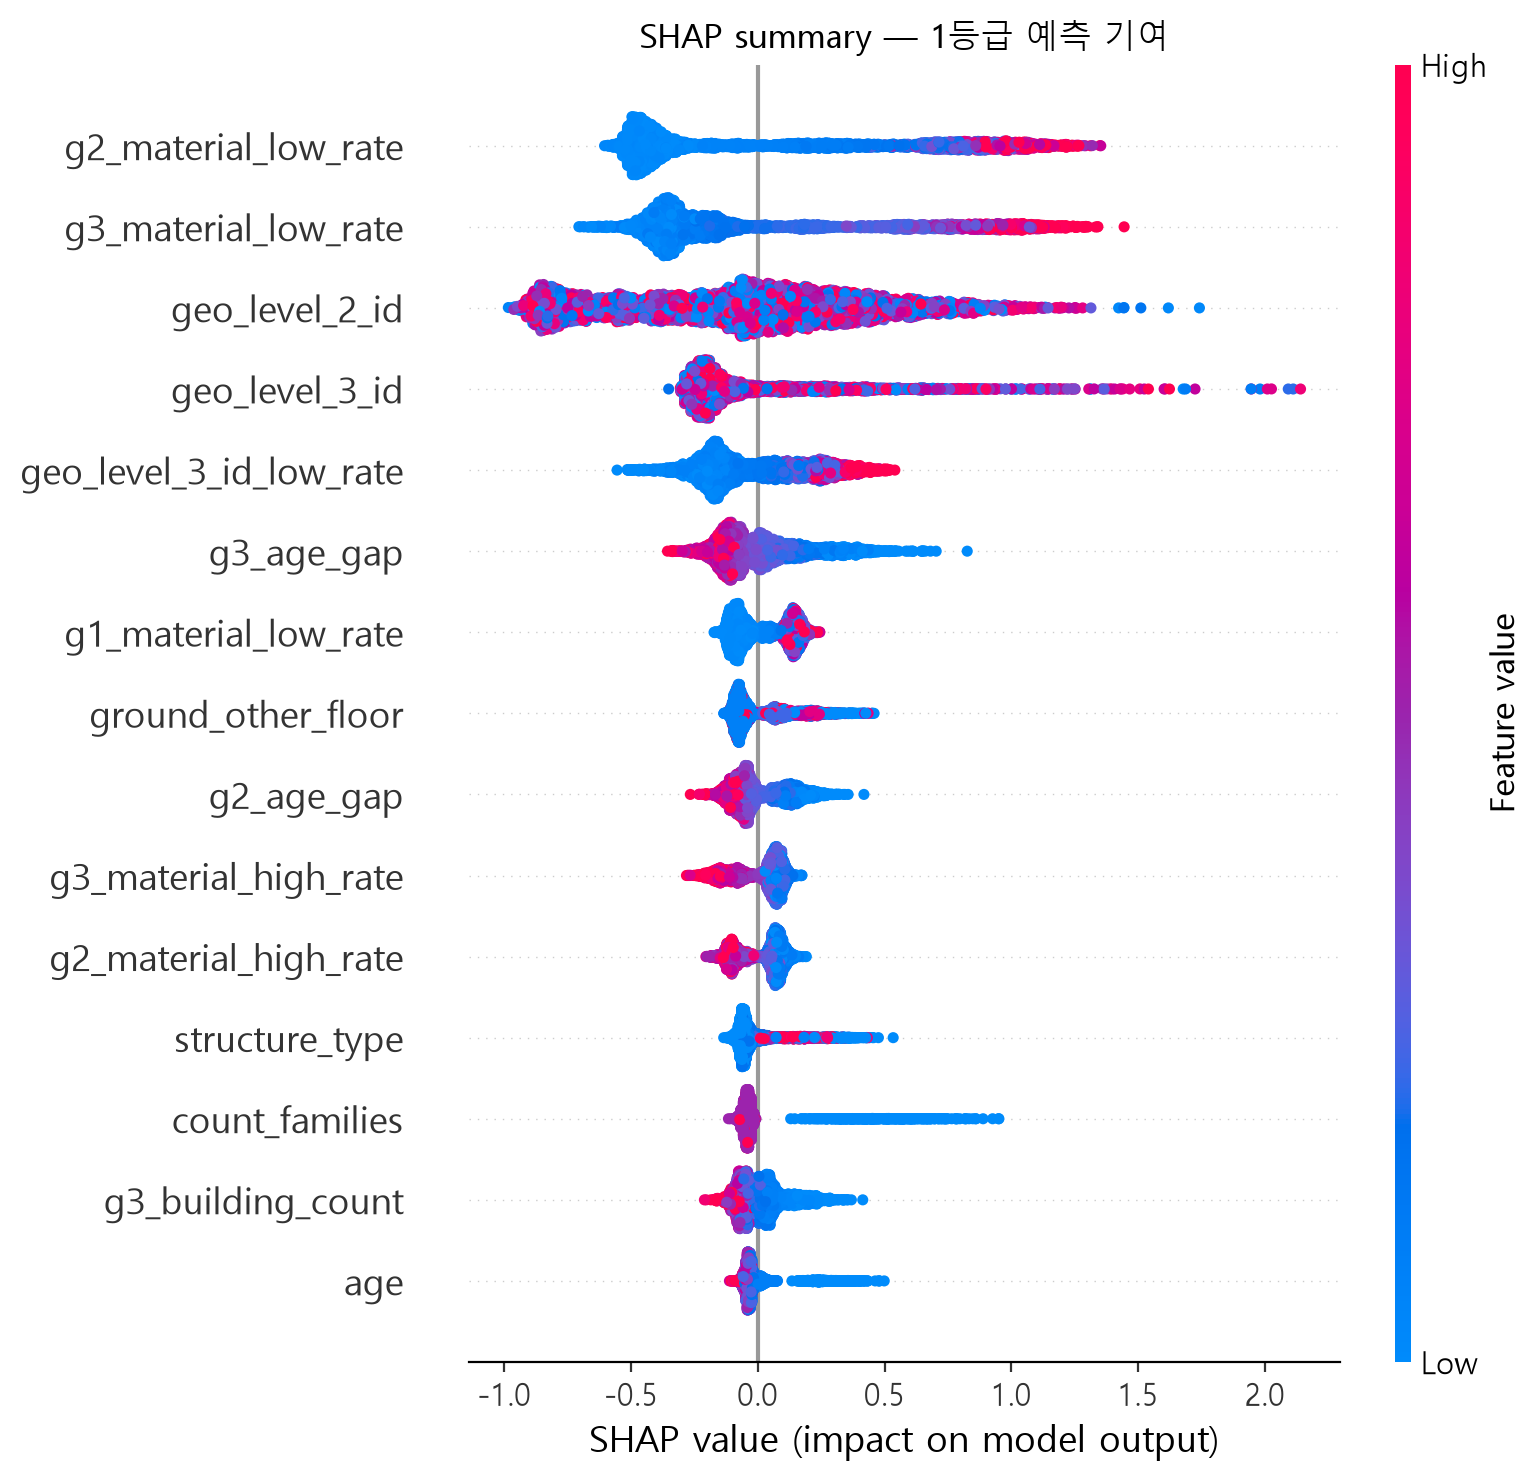

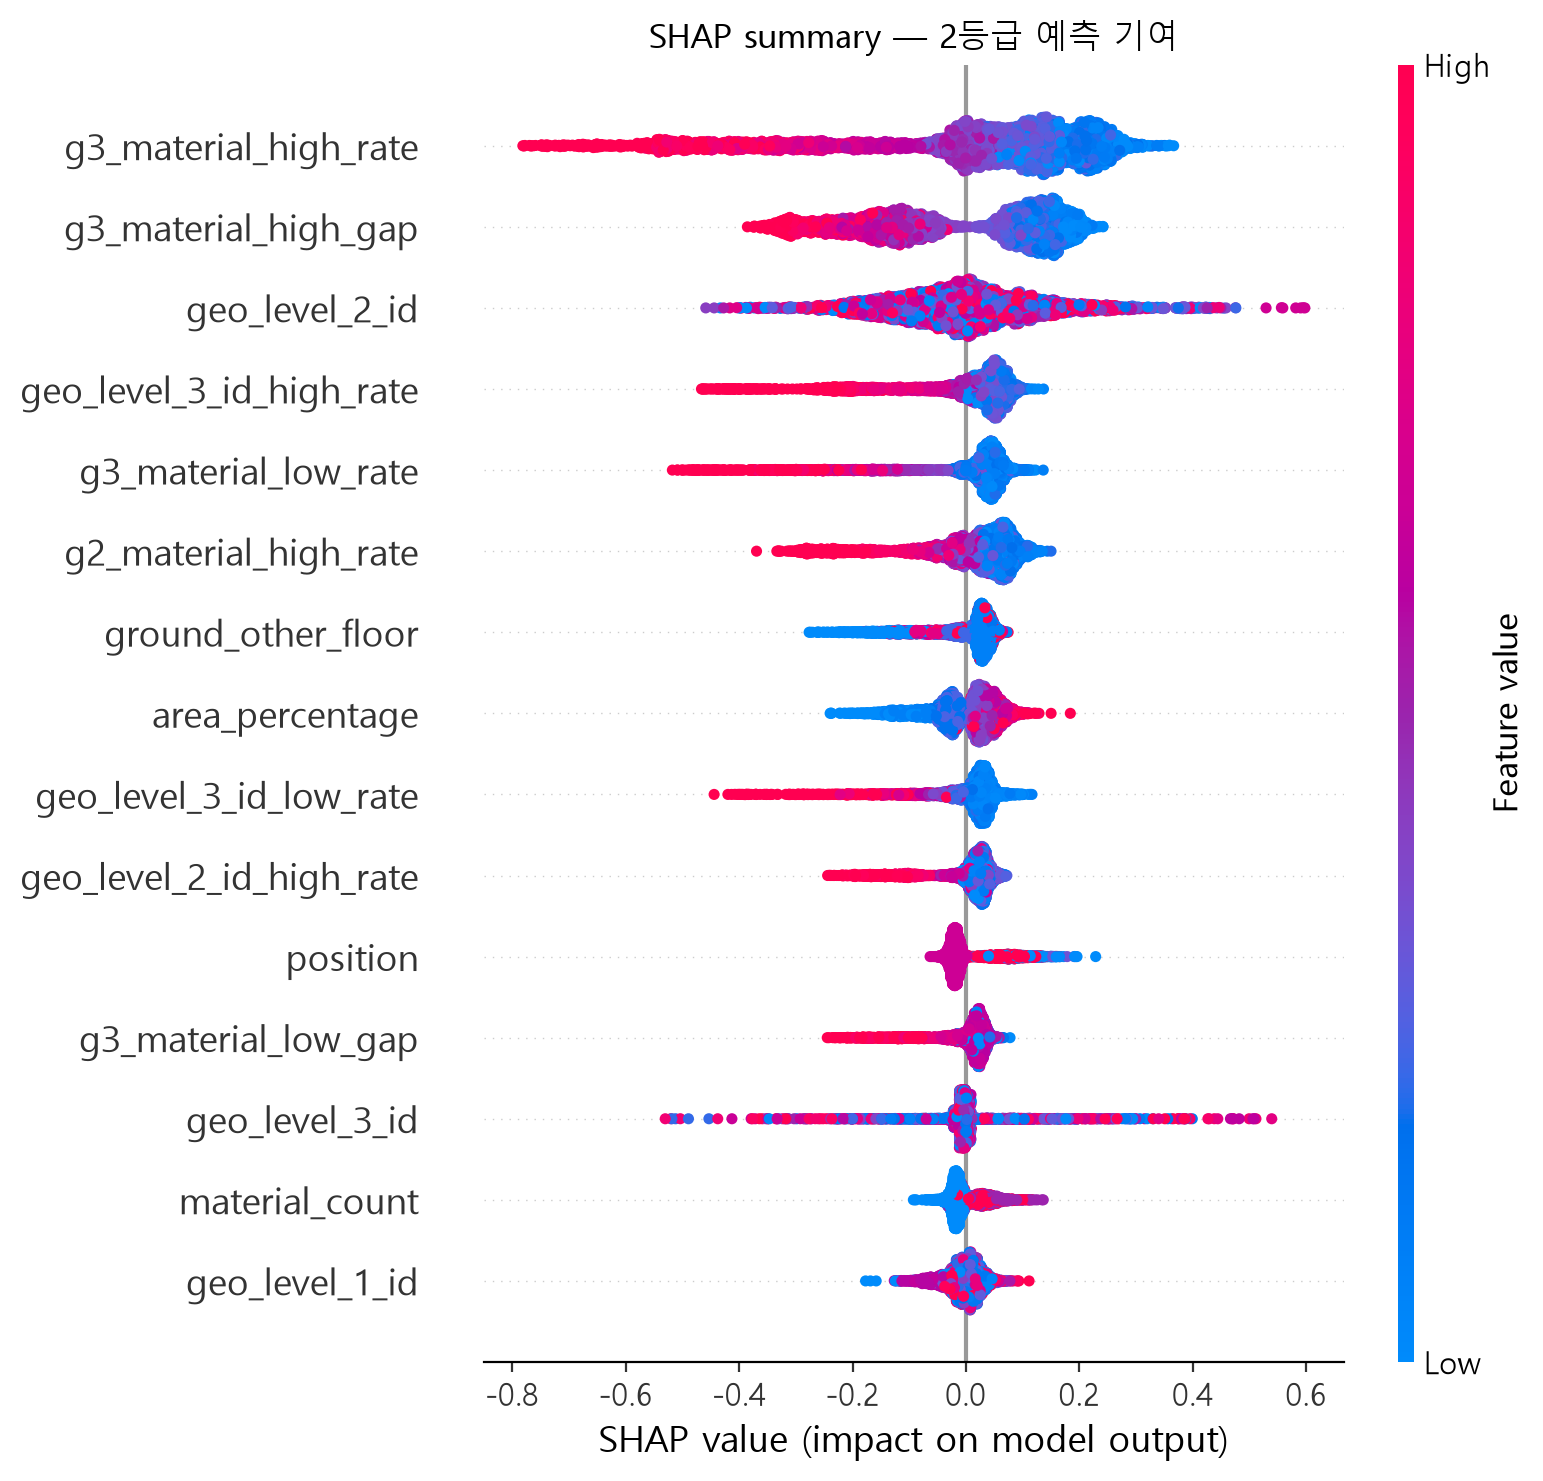

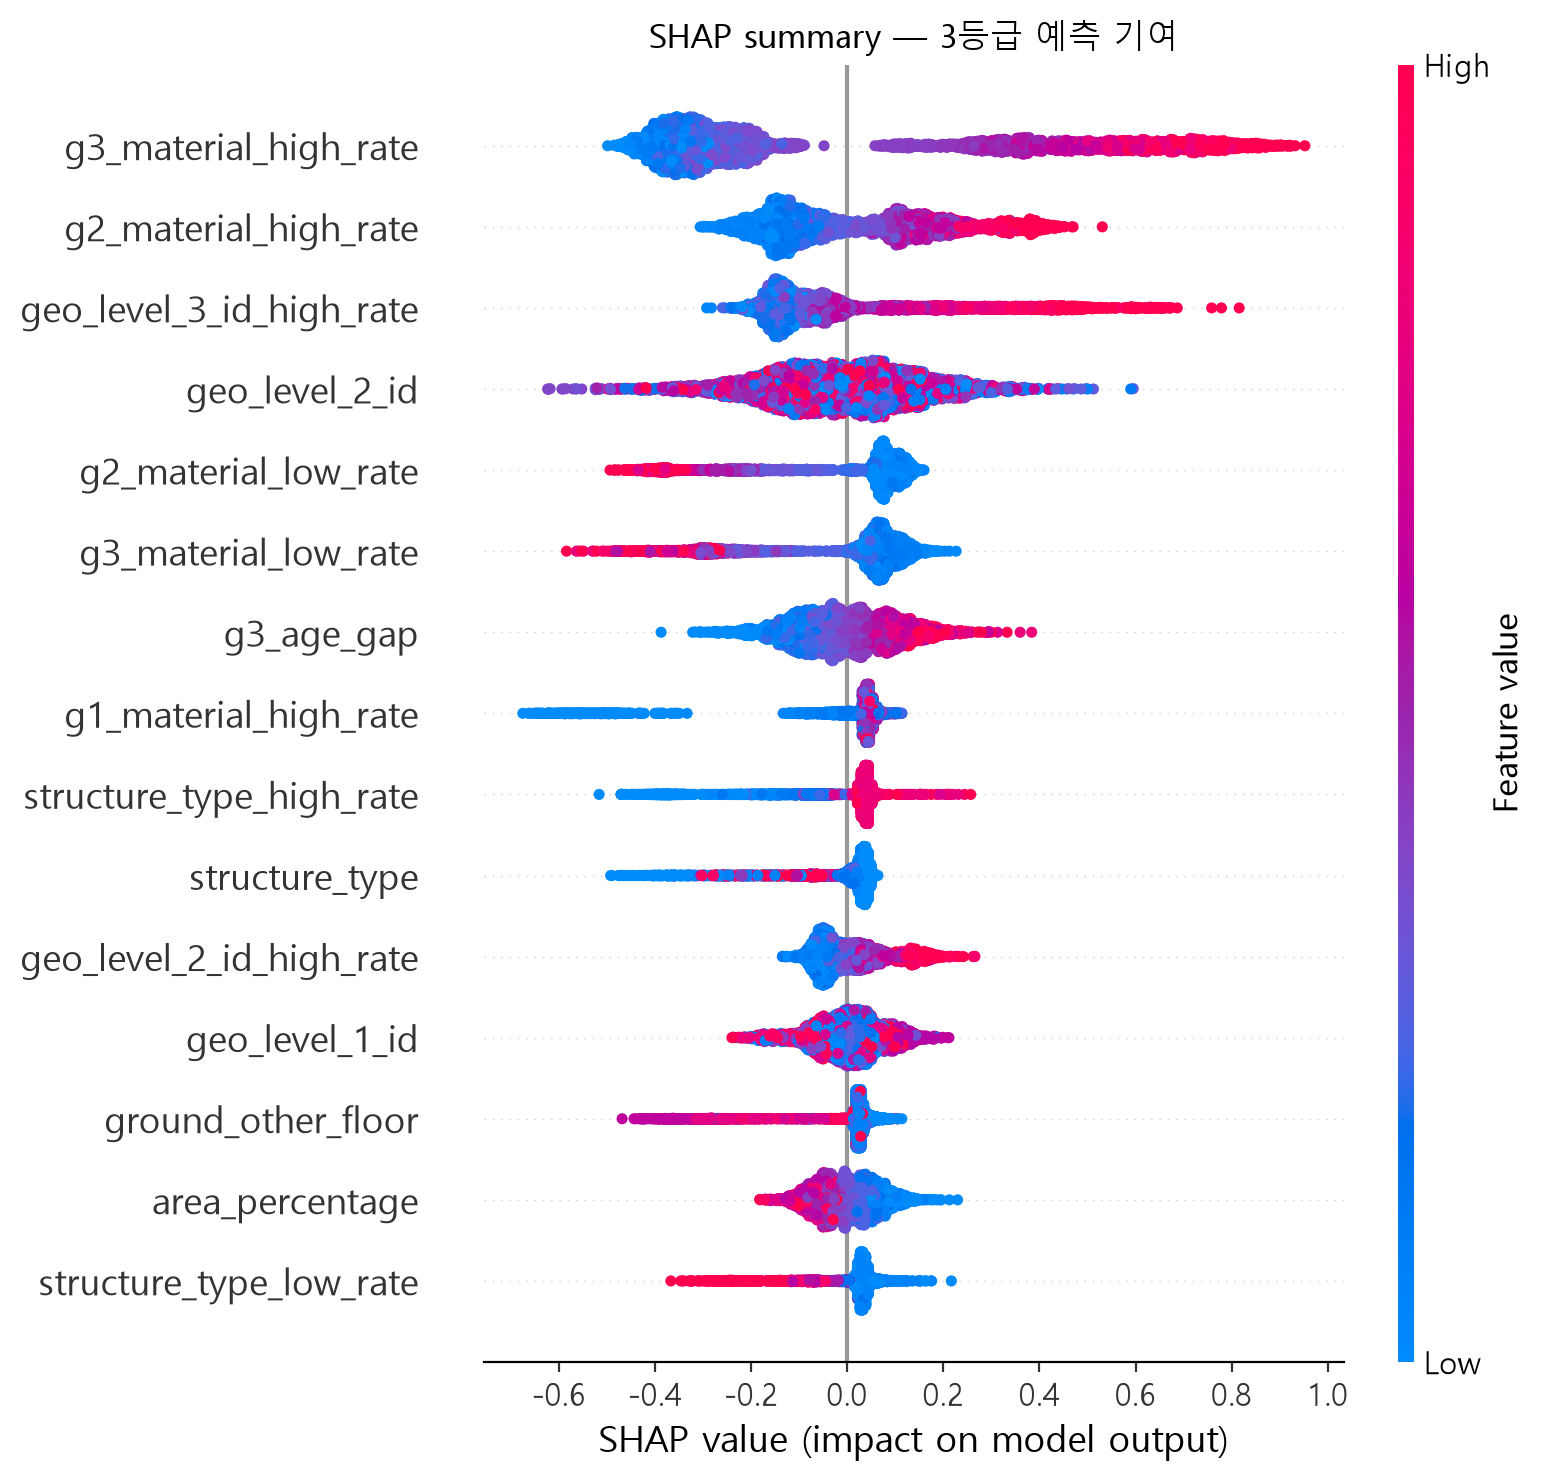

In [57]:
for k, label in enumerate(labels):
    plt.figure()
    shap.summary_plot(shap_values[k], shap_X_codes, max_display=15, show=False)
    plt.title(f"SHAP summary — {label} 예측 기여", fontsize=12)
    plt.tight_layout()
    plt.show()